This notebook computes the long range projections strengths to excitatory vs. to inhibitory populations to each node according to the SLN and structural connectome
and shows the counter-stream inhibitory hypothesis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import pearsonr, zscore
from nibabel.freesurfer.io import read_annot
from nilearn import datasets, plotting
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.title_fontsize": 16,
    "legend.fontsize": 14,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)
colors = {
    "grey":   "#4d4d4d",
}
cmaps_fig2 = {
    "excitation_seq": LinearSegmentedColormap.from_list(
        "exc_seq", ["#e7f6ed", "#86c3a2", "#56c68a"], N=256
    ),
    "inhibition_seq": LinearSegmentedColormap.from_list(
        "exc_seq", ["#fee8c8", "#fdbb84", "#e69f00"], N=256
    )
}

## Load relevant data into a dataframe for ease of manipulation

In [2]:
# How much input strength to excitatory / inhibitory populations the nodes receive from other nodes
W_E = np.load('../data/processed/schaefer100_W_E_SC_SLN.npy') # Matrix of SC * SLN
W_I = np.load('../data/processed/schaefer100_W_I_SC_SLN.npy') # Matrix of SC * (1 - SLN)
E_to_source = np.zeros(50)
I_to_source = np.zeros(50)
for index, row in enumerate(W_E): # Each row represents a target, and each column a source
    E_to_source[index] = np.sum(row)
for index, row in enumerate(W_I): # Each row represents a target, and each column a source
    I_to_source[index] = np.sum(row)
# Area names, remove the 7Networks_LH_ prefix from names
area_names = pd.read_csv('../data/processed/schaefer100_LH_area_names.csv')['Area_name'].tolist()
for index, name in enumerate(area_names):
    area_names[index] = name.replace('7Networks_LH_', '')
    
# Load hierarchy for left hemisphere
hierarchies = pd.read_csv('../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val'].tolist()
# Build dataframe with all the data
dict_network = {'area_names': area_names, 'hierarchy': hierarchies,
                'E_to_source': E_to_source, 'I_to_source': I_to_source}
network_connectivity = pd.DataFrame(dict_network)

## Plot W_E: matrix of long-range projections that target excitatory populations

In [3]:
network_connectivity_excitatory = network_connectivity['E_to_source'].tolist()

annot_path = ('../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

mapped_excitatory_input = np.full(labels.shape, np.nan)
for i in range(len(region_names)):
    if i == 0:
        mapped_excitatory_input[labels == i] = np.nan
    else:
        mapped_excitatory_input[labels == i] = network_connectivity_excitatory[i - 1]
vmin, vmax = np.nanmin(mapped_excitatory_input), np.nanmax(mapped_excitatory_input)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_excitatory_input, fs.sulc_left,
        hemi='left', view=view,
        cmap=cmaps_fig2['excitation_seq'], colorbar=True,
        symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'saved_plots/Figure_2/W_E_matrix_{view}.{ext}', dpi=dpi, bbox_inches='tight')
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


## Plot W_I: matrix of long-range projections that target inhibitory populations

In [4]:
network_connectivity_inhibitory = network_connectivity['I_to_source'].tolist()

annot_path = ('../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

mapped_inhibitory_input = np.full(labels.shape, np.nan)
for i in range(len(region_names)):
    if i == 0:
        mapped_inhibitory_input[labels == i] = np.nan
    else:
        mapped_inhibitory_input[labels == i] = network_connectivity_inhibitory[i - 1]
vmin, vmax = np.nanmin(mapped_inhibitory_input), np.nanmax(mapped_inhibitory_input)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_inhibitory_input, fs.sulc_left,
        hemi='left', view=view,
        cmap=cmaps_fig2['inhibition_seq'], colorbar=True,
        symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'saved_plots/Figure_2/W_I_matrix_{view}.{ext}', dpi=dpi, bbox_inches='tight')
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


Plot the counter-stream inhibitory hypothesis figures, with the SLN, 1-SLN and structural connectivity illustrations

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sln = pd.read_csv('../data/processed/schaefer100_LH_SLN.csv')
hierarchy = pd.read_csv('../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val']
order = np.argsort(hierarchy.values)
mat = sln.values[np.ix_(order, order)]
labs = hierarchy.values[order]
df_sln = pd.DataFrame(mat, index=labs, columns=labs)

sc_matrix = pd.read_csv('../data/processed/schaefer100_LH_sc.csv')
sc_values = sc_matrix.values[np.ix_(order, order)]
df_sc = pd.DataFrame(sc_matrix, index=labs, columns=labs)


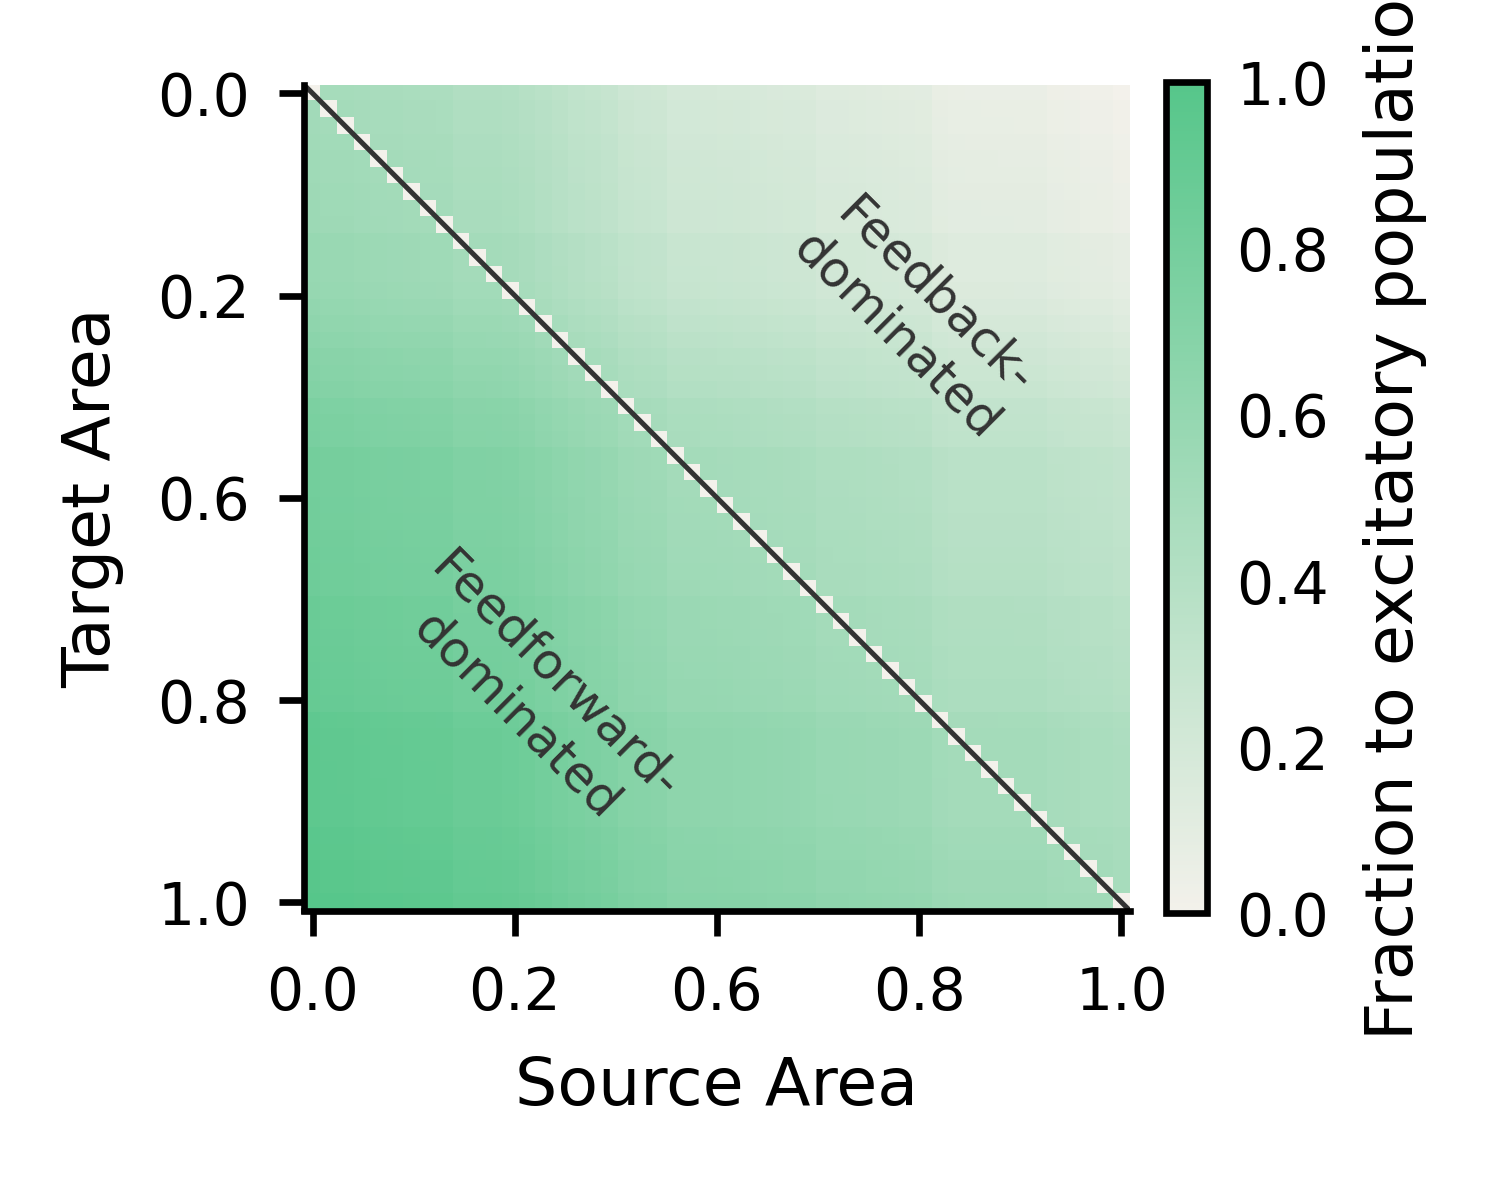

In [4]:
small_style = {
    "font.size": 7, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.major.size": 3, "ytick.major.size": 3,
}

cmaps_fig2_sln = {
    "sln_seq": LinearSegmentedColormap.from_list(
        "sln_seq", ["#f3f1eb", "#56c68a"], N=256)
}

n = len(labs)

with plt.rc_context(small_style):
    fig, ax = plt.subplots(figsize=(2.4, 2.1))
    im = ax.imshow(df_sln.values, cmap=cmaps_fig2_sln['sln_seq'],
                   origin='upper', aspect='equal',
                   vmin=np.nanmin(mat), vmax=np.nanmax(mat))

    # hierarchy ticks: positions are ranks, labels are the hierarchy value at that rank
    ticks = np.linspace(0, n - 1, 5)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_yticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_xlabel('Source Area')
    ax.set_ylabel('Target Area')
    ax.minorticks_off()
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    # separating diagonal
    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color='#333333', lw=0.6)

    # triangle labels (text runs parallel to the diagonal)
    ax.text(0.27 * n, 0.73 * n, 'Feedforward-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')
    ax.text(0.73 * n, 0.27 * n, 'Feedback-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.minorticks_off(); cbar.ax.tick_params(size=0)
    cbar.outline.set_linewidth(0.8)
    cbar.set_label('Fraction to excitatory population') 

    plt.tight_layout()
    # plt.savefig('saved_plots/Figure_2/sln_matrix_by_hierarchy.svg', bbox_inches='tight')
    plt.show()


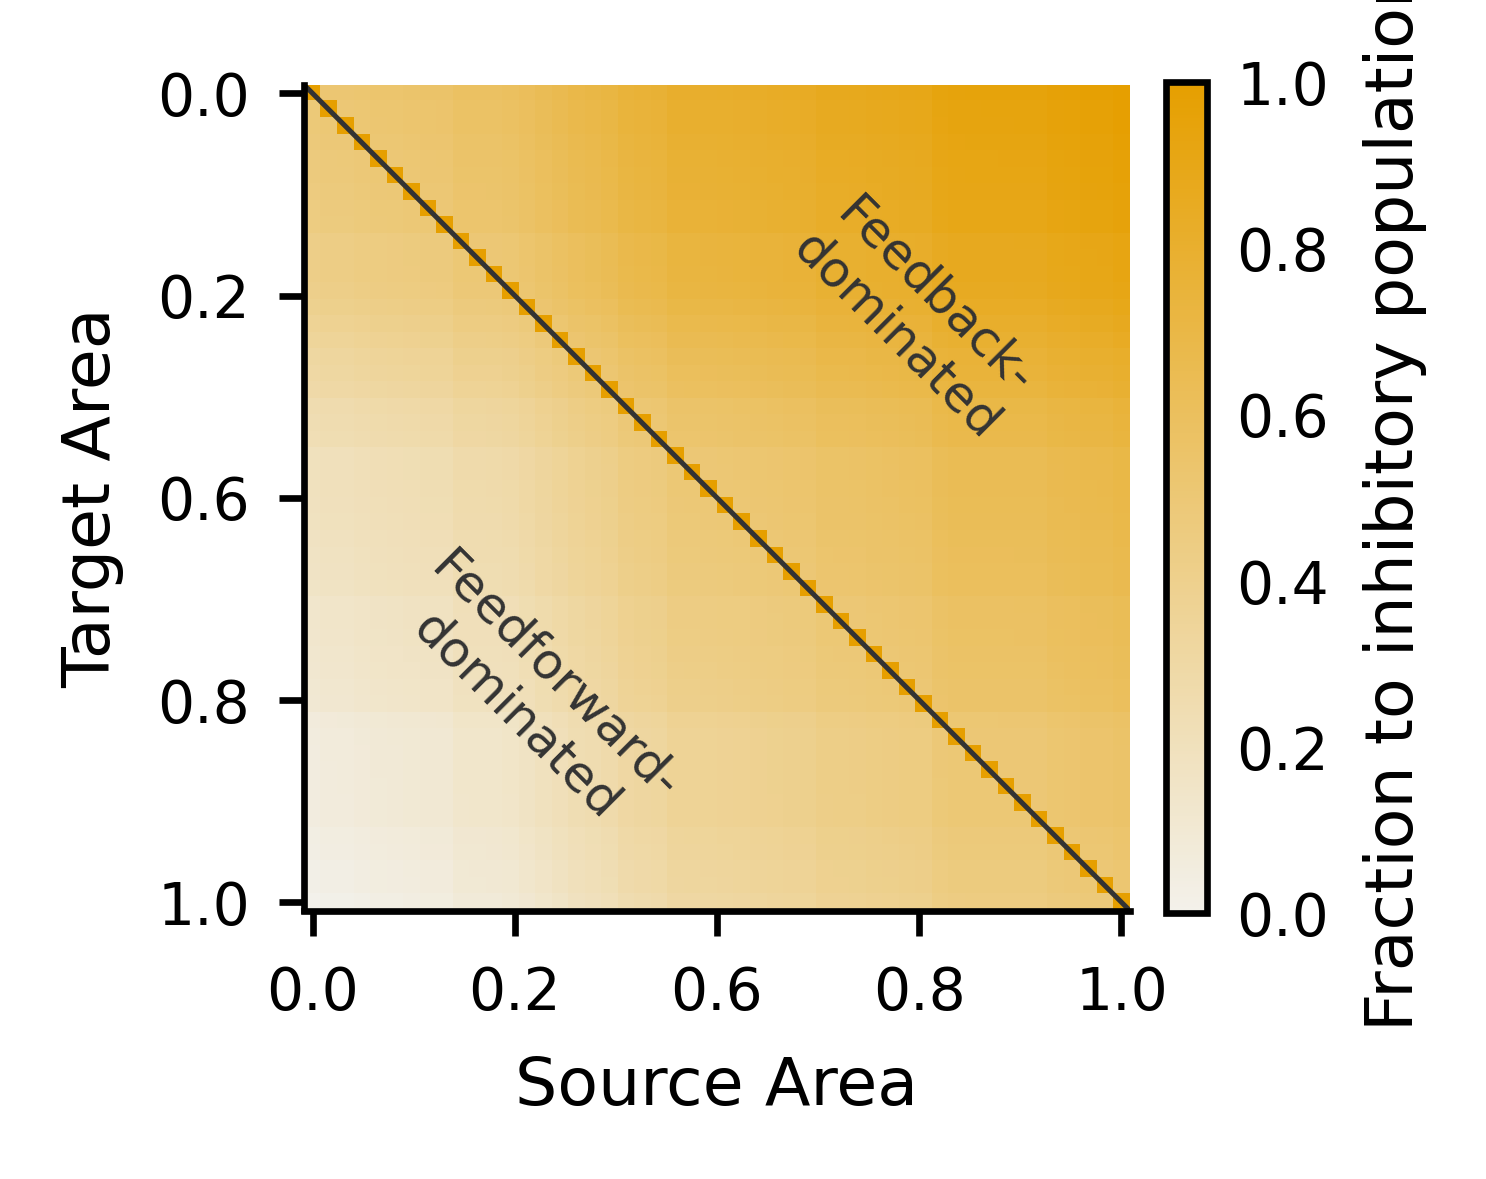

In [5]:
small_style = {
    "font.size": 7, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.major.size": 3, "ytick.major.size": 3,
}

cmaps_fig2_sln_inh = {
    "sln_seq": LinearSegmentedColormap.from_list(
        "sln_seq", ["#f3f1eb", "#e69f00"], N=256)
}

n = len(labs)

with plt.rc_context(small_style):
    fig, ax = plt.subplots(figsize=(2.4, 2.1))
    im = ax.imshow(1 - df_sln.values, cmap=cmaps_fig2_sln_inh['sln_seq'],
                   origin='upper', aspect='equal',
                   vmin=np.nanmin(mat), vmax=np.nanmax(mat))

    # hierarchy ticks: positions are ranks, labels are the hierarchy value at that rank
    ticks = np.linspace(0, n - 1, 5)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_yticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_xlabel('Source Area')
    ax.set_ylabel('Target Area')
    ax.minorticks_off()
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    # separating diagonal
    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color='#333333', lw=0.6)

    # triangle labels (text runs parallel to the diagonal)
    ax.text(0.27 * n, 0.73 * n, 'Feedforward-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')
    ax.text(0.73 * n, 0.27 * n, 'Feedback-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.minorticks_off(); cbar.ax.tick_params(size=0)
    cbar.outline.set_linewidth(0.8)
    cbar.set_label('Fraction to inhibitory population') 

    plt.tight_layout()
    # plt.savefig('saved_plots/Figure_2/sln_matrix_by_hierarchy_inhibitory.svg', bbox_inches='tight')
    plt.show()


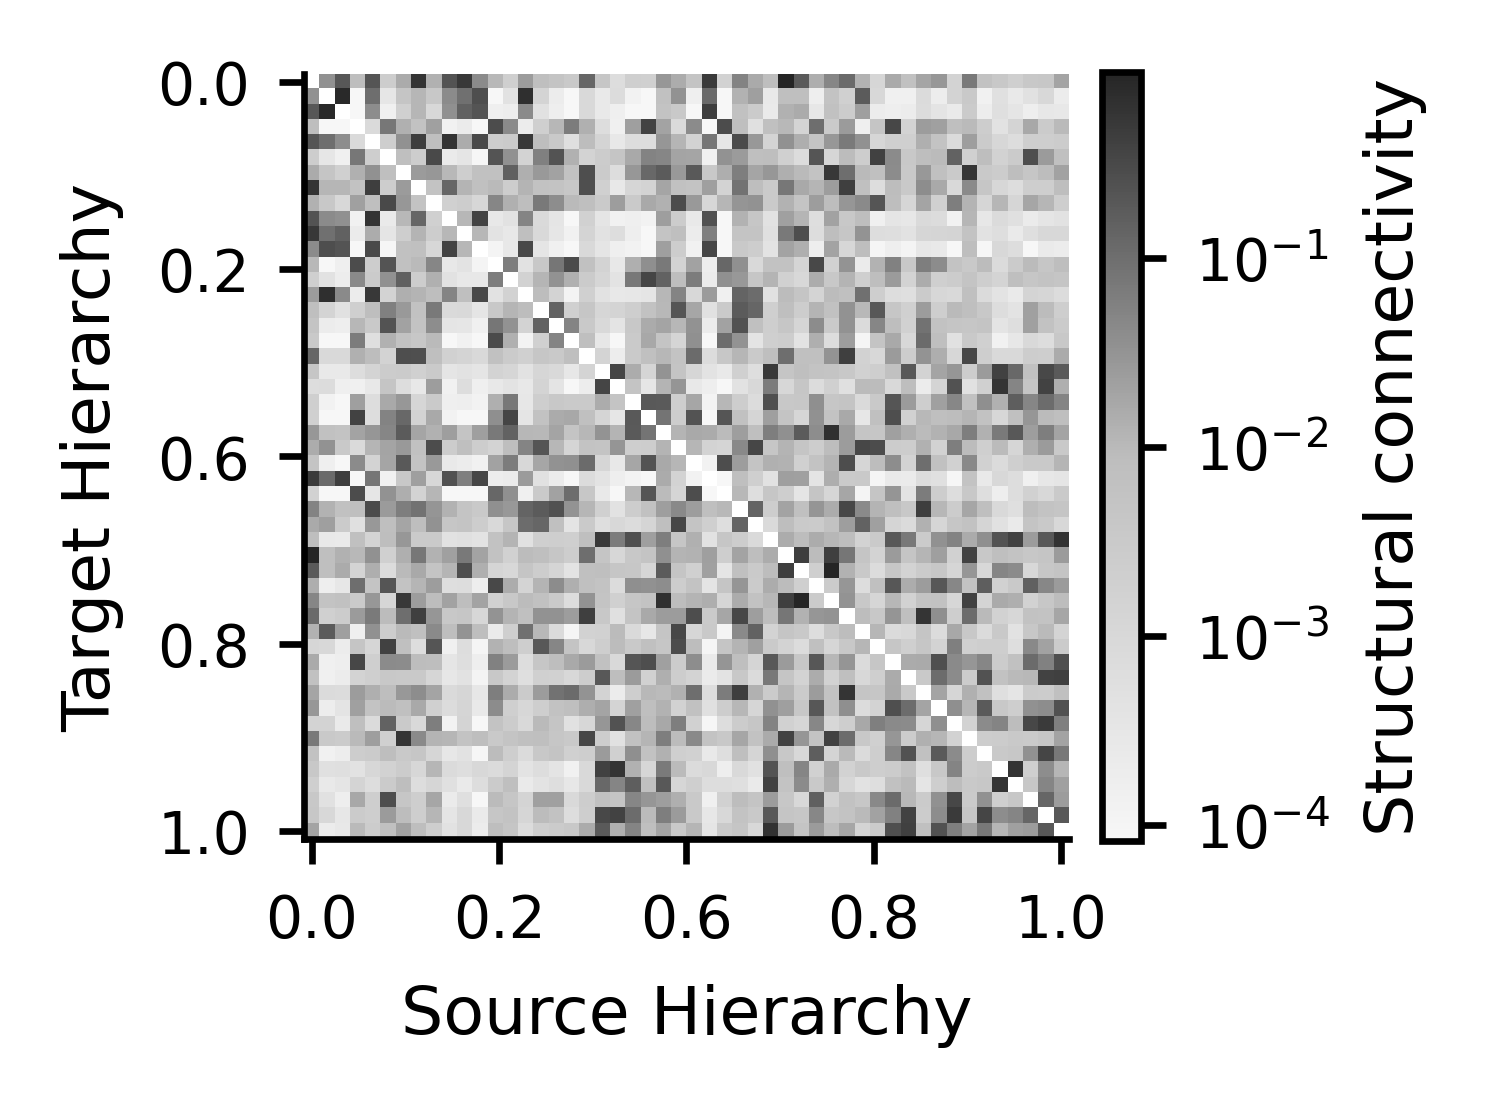

In [8]:
from matplotlib.colors import LogNorm

order = np.argsort(hierarchy.values)
labs = hierarchy.values[order]
n = len(labs)
sc = pd.read_csv('../data/processed/schaefer100_LH_sc.csv')
sc_o = sc.values[np.ix_(order, order)]
df_sc = pd.DataFrame(sc_o, index=labs, columns=labs)

sc_cmap = LinearSegmentedColormap.from_list('sc_seq', ['#f7f7f7', '#bdbdbd', '#252525'], N=256)
sc_cmap.set_bad('#ffffff')
sc_pos  = sc_o[sc_o > 0]

with plt.rc_context(small_style):
    fig, ax = plt.subplots(figsize=(2.4, 2.1))
    im = ax.imshow(np.where(sc_o > 0, sc_o, np.nan), cmap=sc_cmap,
                   norm=LogNorm(vmin=np.percentile(sc_pos, 2), vmax=sc_pos.max()),
                   origin='upper', aspect='equal')
    ticks = np.linspace(0, n - 1, 5)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_yticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_xlabel('Source Hierarchy'); ax.set_ylabel('Target Hierarchy')
    ax.minorticks_off()
    for s in ['top', 'right']: ax.spines[s].set_visible(False)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.minorticks_off(); cbar.outline.set_linewidth(0.8)
    cbar.set_label('Structural connectivity')

    plt.tight_layout()
    # plt.savefig('saved_plots/Figure_2/sc_by_hierarchy.svg', bbox_inches='tight')
    plt.show()


## Individual panels for the schematic

Each panel is 1/4 of the 18.4 cm page width (4.6 cm) by 4 cm, Open Sans at 8 pt.
Run the three cells above first, so that `df_sln`, `mat`, `labs`, `sc_o`, `sc_cmap`,
`cmaps_fig2_sln` and `cmaps_fig2_sln_inh` are defined.

In [ ]:
# Same style as the combined panel in Figure_1: Open Sans at 8 pt.
# font.family, so usetex has to be off for Open Sans to be used.
import matplotlib as mpl

panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 6,
    "axes.labelsize": 6,
    "axes.titlesize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "legend.title_fontsize": 6,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# One panel = 1/4 of the 18.4 cm page width, 4 cm high. figsize is in inches, so divide by 2.54.
CM = 2.54
PANEL_W = 18.4 / 4 / CM
PANEL_H = 4 / CM
print(f'panel size: {PANEL_W*CM:.2f} x {PANEL_H*CM:.2f} cm  =  {PANEL_W:.2f} x {PANEL_H:.2f} in')

panel size: 4.60 x 4.00 cm  =  1.81 x 1.57 in


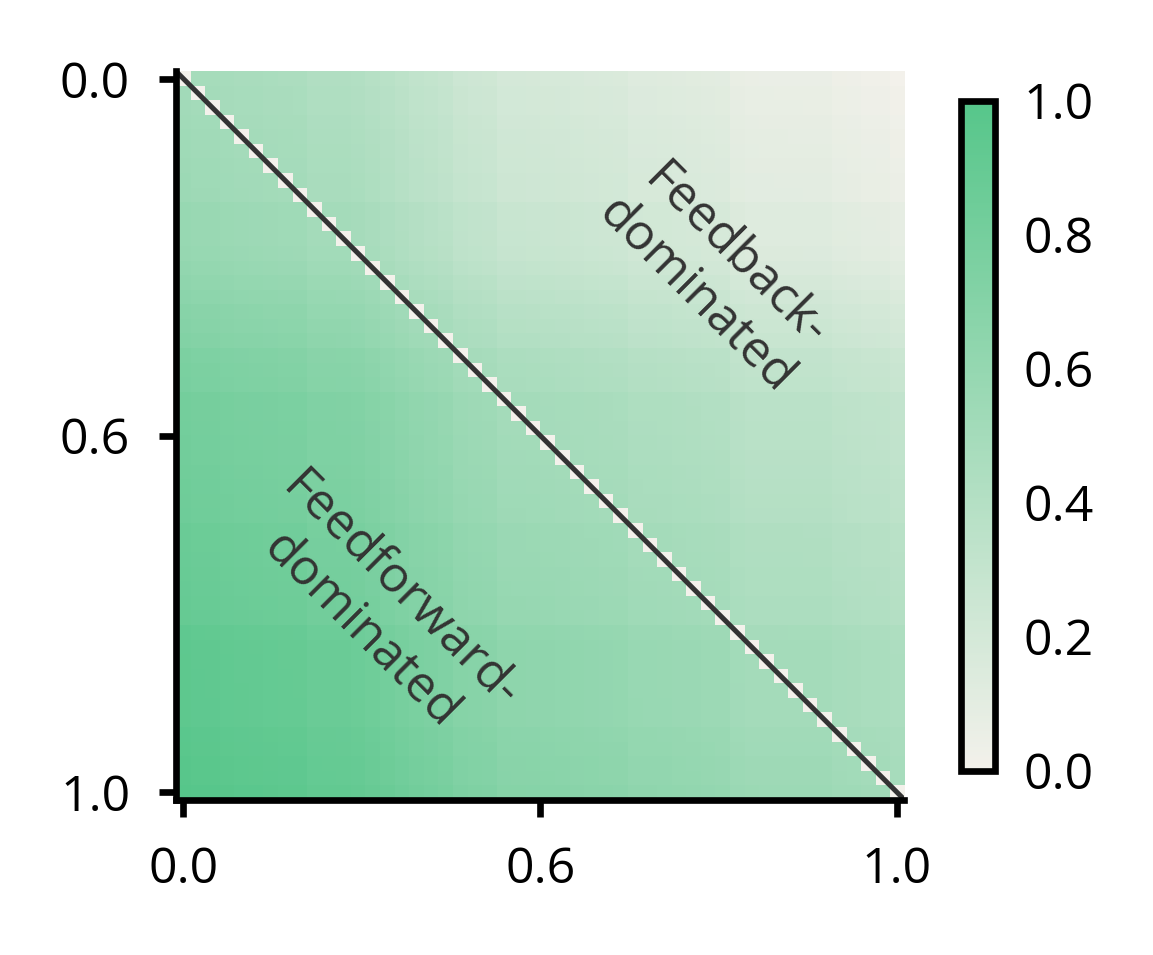

In [10]:
# Panel 1: SLN matrix, fraction of projections targeting the excitatory population.
n = len(labs)

with mpl.rc_context(panel_style):
    # constrained_layout instead of tight_layout: it fits the colorbar without changing figsize
    fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H), constrained_layout=True)
    im = ax.imshow(df_sln.values, cmap=cmaps_fig2_sln['sln_seq'],
                   origin='upper', aspect='equal',
                   vmin=np.nanmin(mat), vmax=np.nanmax(mat))

    # 3 ticks instead of 5, otherwise the labels collide at this panel size
    ticks = np.linspace(0, n - 1, 3)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_yticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
#     ax.set_xlabel('Source hierarchy')
#     ax.set_ylabel('Target hierarchy')
    ax.minorticks_off()
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    # separating diagonal
    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color='#333333', lw=0.6)

    # triangle labels (text runs parallel to the diagonal)
    ax.text(0.27 * n, 0.73 * n, 'Feedforward-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')
    ax.text(0.73 * n, 0.27 * n, 'Feedback-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')

    # no cbar.set_label: the colorbar is left unlabelled, annotate it in the schematic
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.minorticks_off(); cbar.ax.tick_params(size=0)
    cbar.outline.set_linewidth(0.8)

    # no bbox_inches='tight', so the file keeps the exact 4.6 x 4 cm size
    fig.savefig('saved_plots/Figure_2/sln_matrix_by_hierarchy_panel.svg')
    plt.show()

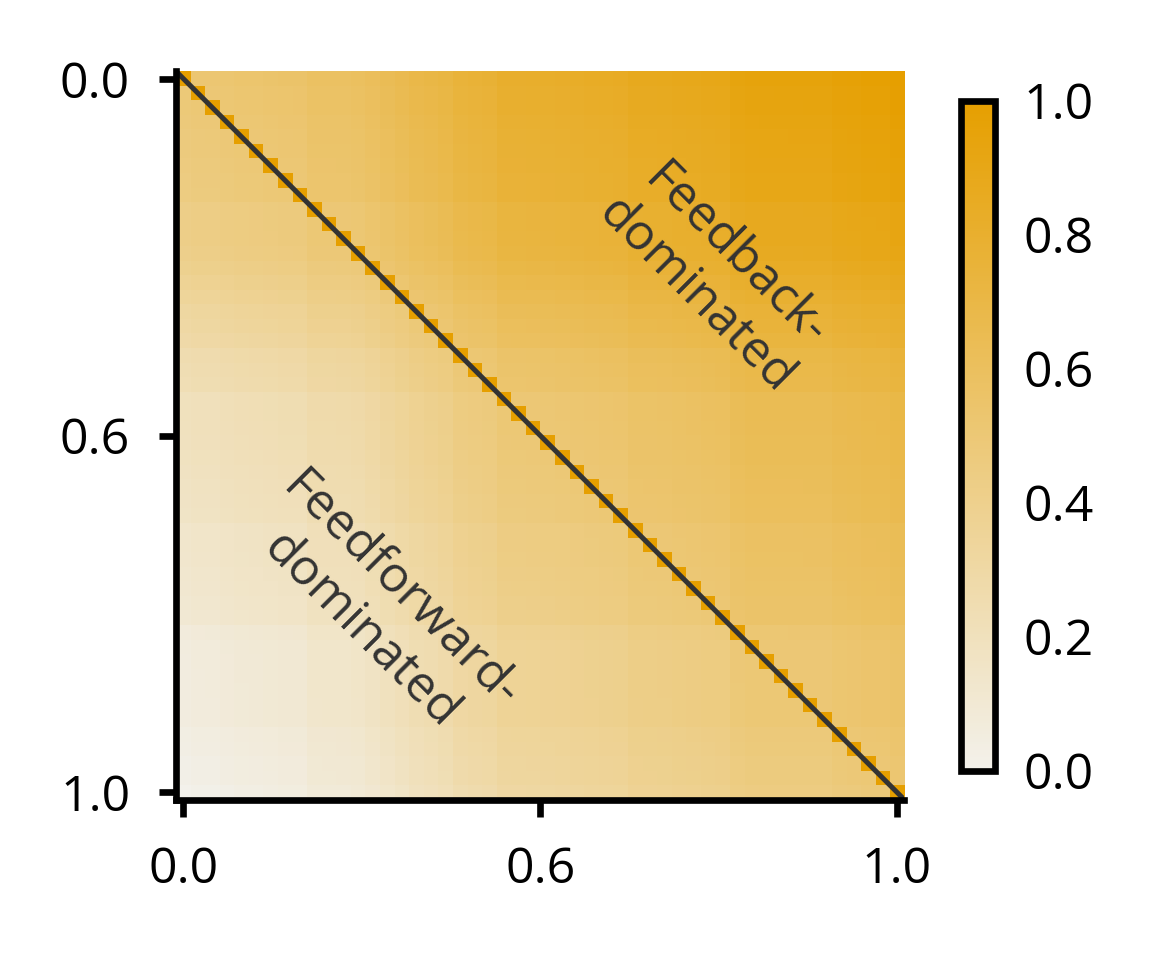

In [11]:
# Panel 2: same matrix, fraction of projections targeting the inhibitory population (1 - SLN).
n = len(labs)

with mpl.rc_context(panel_style):
    fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H), constrained_layout=True)
    im = ax.imshow(1 - df_sln.values, cmap=cmaps_fig2_sln_inh['sln_seq'],
                   origin='upper', aspect='equal',
                   vmin=np.nanmin(mat), vmax=np.nanmax(mat))

    ticks = np.linspace(0, n - 1, 3)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_yticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
#     ax.set_xlabel('Source hierarchy')
#     ax.set_ylabel('Target hierarchy')
    ax.minorticks_off()
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color='#333333', lw=0.6)

    ax.text(0.27 * n, 0.73 * n, 'Feedforward-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')
    ax.text(0.73 * n, 0.27 * n, 'Feedback-\ndominated',
            rotation=-45, ha='center', va='center', fontsize=6, color='#333333')

    # no cbar.set_label: the colorbar is left unlabelled, annotate it in the schematic
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.minorticks_off(); cbar.ax.tick_params(size=0)
    cbar.outline.set_linewidth(0.8)

    fig.savefig('saved_plots/Figure_2/sln_matrix_by_hierarchy_inhibitory_panel.svg')
    plt.show()

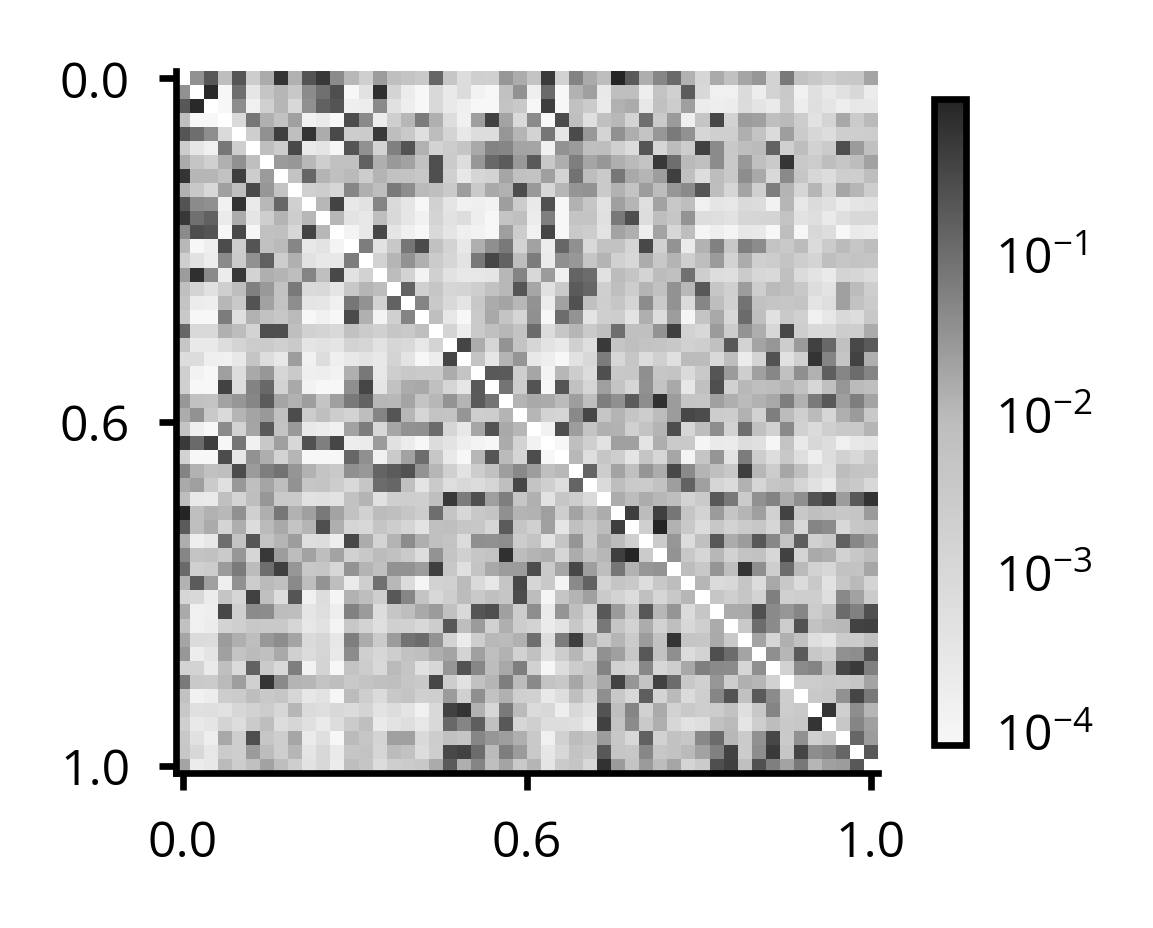

In [12]:
# Panel 3: structural connectivity matrix, same ordering by hierarchy.
n = len(labs)
sc_pos = sc_o[sc_o > 0]

with mpl.rc_context(panel_style):
    fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H), constrained_layout=True)
    im = ax.imshow(np.where(sc_o > 0, sc_o, np.nan), cmap=sc_cmap,
                   norm=LogNorm(vmin=np.percentile(sc_pos, 2), vmax=sc_pos.max()),
                   origin='upper', aspect='equal')

    ticks = np.linspace(0, n - 1, 3)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    ax.set_yticklabels([f'{labs[int(t)]:.1f}' for t in ticks])
    # ax.set_xlabel('Source hierarchy')
    # ax.set_ylabel('Target hierarchy')
    ax.minorticks_off()
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    # no cbar.set_label: the colorbar is left unlabelled, annotate it in the schematic
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.minorticks_off(); cbar.ax.tick_params(size=0)
    cbar.outline.set_linewidth(0.8)

    fig.savefig('saved_plots/Figure_2/sc_by_hierarchy_panel.svg')
    plt.show()